# ZELA · Classificação de relatos urbanos

**Global Solution 2026 · CitizenTech · Engenharia de Software · FIAP**

O morador descreve um problema da rua. Um representante do bairro precisa
identificar o tipo de serviço, revisar o relato e preparar o encaminhamento.
Este experimento sugere a categoria a partir do texto e sinaliza casos que
merecem conferência adicional.

**Público** — moradores, trabalhadores do bairro e operadores da ouvidoria.

**Escopo** — seis categorias de zeladoria. A delimitação da cidade, do bairro
e a pesquisa com uma pessoa beneficiada serão preenchidas na etapa de campo.

**Origem dos dados** — simulação controlada, com 180 cenários descritos em
`data/scenarios.json`. Os resultados representam este conjunto sintético.

**Como executar** — instale `requirements.txt`, instale o pacote com
`python -m pip install -e . --no-deps` e execute as células na ordem.
O repositório já inclui o modelo treinado e os resultados desta execução.

## 1. Ambiente e reprodutibilidade

Fixamos a semente em 42. A versão das bibliotecas está no arquivo de
dependências e o manifesto guarda o hash SHA-256 do modelo e do dataset.
O treino, a demonstração e a API reutilizam o mesmo pacote Python.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Abra o notebook dentro do repositório.'
sys.path.insert(0, str(ROOT / 'src'))

from zela_ml.dataset import build_dataset, validate_dataset
from zela_ml.settings import CATEGORIES, REPORTS, SEED
from zela_ml.training import train

print(f'Semente do experimento: {SEED}')
print(f'Categorias: {len(CATEGORIES)}')

Semente do experimento: 42
Categorias: 6


## 2. Dados e unidade de separação

Cada cenário recebe variações de escrita, como retirada de acentos,
abreviação, saudação e contexto adicional. Todas as variações permanecem na
mesma partição. A divisão por categoria reserva 18 cenários para treino,
6 para validação e 6 para teste.

A unidade independente desta simulação é o cenário. Aumentar a quantidade
de variações aumenta as linhas, mas mantém a diversidade limitada ao
catálogo original.

In [2]:
data = build_dataset()
validate_dataset(data)
display(data.sample(6, random_state=SEED)[['text', 'category', 'split', 'source']])
display(pd.crosstab(data['category'], data['split']))
print(f'{len(data)} relatos simulados · {data.scenario.nunique()} cenários')

,text,category,split,source
247,A passarela está com muito lixo acumulado e ma...,limpeza,train,simulado
670,A tampa nivelada na calçada cedeu e impede a p...,acessibilidade,train,simulado
227,"Bom dia. a calçada está boa, mas há lixo e sac...",limpeza,test,simulado
290,"depois da obra, o remendo da pista afundou.",pavimentacao,validation,simulado
538,A sarjeta não conduz a chuva até o coletor e a...,drenagem,validation,simulado
796,Um ramo pesado está se soltando da copa sobre ...,areas_verdes,train,simulado


split,test,train,validation
category,,,
acessibilidade,25,81,28
areas_verdes,26,82,26
drenagem,29,84,28
iluminacao,26,78,26
limpeza,28,81,27
pavimentacao,26,82,27


810 relatos simulados · 180 cenários


,relatos,cenarios
split,,
test,160,36
train,488,108
validation,162,36


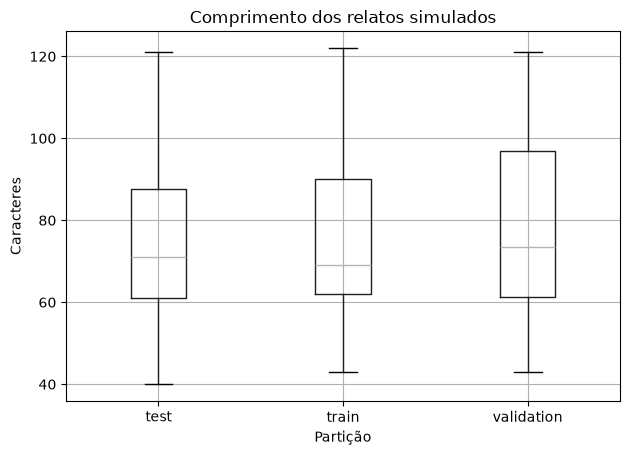

In [3]:
groups = {split: set(part.scenario) for split, part in data.groupby('split')}
assert groups['train'].isdisjoint(groups['validation'])
assert groups['train'].isdisjoint(groups['test'])
assert groups['validation'].isdisjoint(groups['test'])
display(data.groupby('split').agg(relatos=('id', 'size'), cenarios=('scenario', 'nunique')))
data.assign(characters=data.text.str.len()).boxplot(column='characters', by='split')
plt.title('Comprimento dos relatos simulados')
plt.suptitle('')
plt.xlabel('Partição')
plt.ylabel('Caracteres')
plt.tight_layout()
plt.show()

## 3. Preparação e modelos comparados

O TF-IDF aprende o vocabulário somente no treino, dentro de um Pipeline.
A normalização de caixa e acentos é aplicada pelo mesmo transformador na
inferência. Comparamos uma referência pela frequência das classes, duas
regressões logísticas com TF-IDF de palavras e uma combinação de palavras
com n-gramas de caracteres.

Caracteres ajudam a compartilhar informação entre flexões e abreviações.
A regressão logística permite inspecionar os pesos associados à sugestão.
A seleção usa F1 macro na validação, com desempate por log loss.

O limite da pontuação e a margem entre as duas primeiras categorias também
são escolhidos na validação. Para isso, usamos os 12 casos de revisão
reservados em `data/probes.csv`. O teste fica reservado até essas decisões.

In [4]:
metrics = train()
comparison = pd.read_csv(REPORTS / 'validation_models.csv')
display(comparison)
print('Modelo selecionado:', metrics['selected_model'])
print('Política de revisão:', metrics['review_policy'])

,model,accuracy,f1_macro,log_loss,scenario_all_variants_correct
0,tfidf_palavras_caracteres,0.864198,0.862095,0.895568,0.861111
1,tfidf_palavras_c6,0.716049,0.702370,1.088386,0.694444
2,tfidf_palavras_c2,0.709877,0.697414,1.225792,0.694444
3,referencia_frequencia,0.172840,0.049123,1.791623,0.166667


Modelo selecionado: tfidf_palavras_caracteres
Política de revisão: {'threshold': 0.75, 'margin': 0.4}


## 4. Avaliação no teste separado

F1 macro dá o mesmo peso às seis categorias. A matriz de confusão mostra os
tipos de erro, e a taxa de cenários inteiramente corretos exige acerto em
todas as variações de cada situação. O intervalo de 95% usa 1.000
reamostragens por cenário, preservando a correlação entre variações.
Seu alcance é a incerteza dentro desta simulação.

,accuracy,f1_macro,log_loss,scenario_all_variants_correct
referência no teste,0.18125,0.051146,1.79142,0.166667
modelo no teste,0.83750,0.830433,0.83381,0.805556


F1 macro: 0.830
Intervalo por cenário: 0.685 a 0.939


,precision,recall,f1-score,support
Acessibilidade,0.851852,0.920000,0.884615,25.0000
Áreas verdes,0.650000,1.000000,0.787879,26.0000
Drenagem,0.935484,1.000000,0.966667,29.0000
Iluminação pública,1.000000,0.692308,0.818182,26.0000
Limpeza urbana,0.875000,0.500000,0.636364,28.0000
Pavimentação,0.857143,0.923077,0.888889,26.0000
accuracy,0.837500,0.837500,0.837500,0.8375
macro avg,0.861580,0.839231,0.830433,160.0000
weighted avg,0.863194,0.837500,0.830222,160.0000


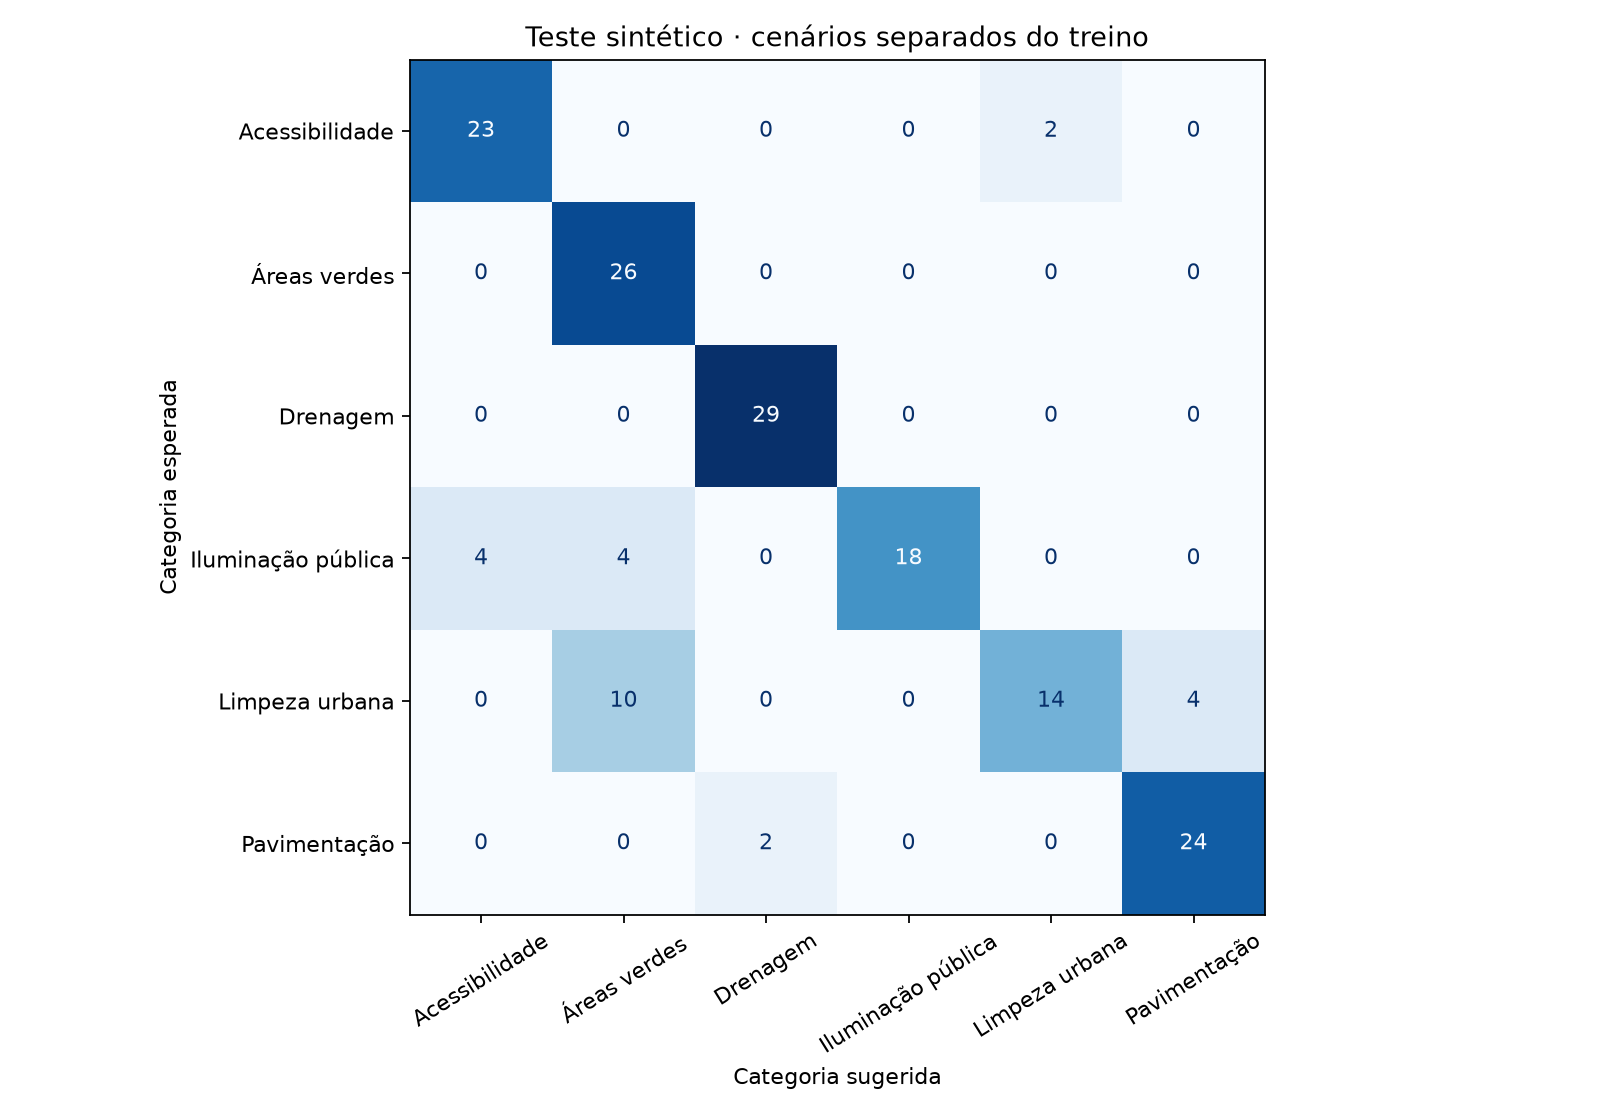

In [5]:
display(pd.DataFrame({
    'referência no teste': metrics['baseline_test'],
    'modelo no teste': metrics['test'],
}).T)
interval = metrics['test_f1_macro_ci95']
print(f"F1 macro: {metrics['test']['f1_macro']:.3f}")
print(f"Intervalo por cenário: {interval['low']:.3f} a {interval['high']:.3f}")
report = json.loads((REPORTS / 'classification_report.json').read_text())
display(pd.DataFrame(report).T)
display(Image(filename=str(REPORTS / 'confusion_matrix.png')))

## 5. Análise de erros

Inspecionamos um exemplo de cada cenário com erro. Relatos que mencionam
vários objetos ou negam um problema podem confundir um classificador
lexical. O CSV de erros inclui todas as variações para análise posterior.

Os casos do teste permanecem congelados. Melhorias futuras serão escolhidas
na validação e exigirão um novo teste independente para uma nova estimativa.

In [6]:
errors = pd.read_csv(REPORTS / 'errors.csv')
display(errors.drop_duplicates('scenario')[['text', 'category', 'predicted', 'score']])
print(f'{len(errors)} variações com erro em {errors.scenario.nunique()} cenários')

,text,category,predicted,score
0,"A árvore foi podada, mas a iluminação da esqui...",iluminacao,areas_verdes,0.427820
4,A lâmpada perto da faixa de pedestres perdeu q...,iluminacao,acessibilidade,0.343048
8,Jogaram um sofá velho e um colchão no terreno ...,limpeza,pavimentacao,0.487566
12,A rua está cheia de folhas secas e pede uma eq...,limpeza,areas_verdes,0.327086
17,"A árvore está saudável, o problema é o monte d...",limpeza,areas_verdes,0.535438
22,O trecho asfaltado cedeu perto da curva.,pavimentacao,drenagem,0.265355
24,Gostaria de registrar o seguinte problema. já ...,acessibilidade,limpeza,0.247651


26 variações com erro em 7 cenários


## 6. Cobertura, revisão e casos difíceis

A sugestão sempre fica disponível ao operador. O marcador de revisão sinaliza
pontuação baixa ou pouca diferença entre as categorias mais prováveis.
A política foi escolhida na validação para preservar a precisão, o que
pode reduzir bastante a cobertura das sugestões com marcador favorável.

O conjunto adicional de teste contém 12 relatos fora do escopo, vagos ou
com vários serviços. Ele permite observar falhas que a acurácia usual
deixa de representar. Uma pontuação elevada pode ocorrer em um relato
inadequado. A conferência do encaminhamento continua com o operador.

In [7]:
display(pd.DataFrame([metrics['test_selective']]))
challenge = pd.read_csv(REPORTS / 'challenge_predictions.csv')
display(challenge[['text', 'reason', 'suggested', 'score', 'requires_review']])
print('Resumo dos casos de desafio:', metrics['challenge_test'])

,coverage,accepted_count,precision_accepted,review_count
0,0.1125,18,1.0,142


,text,reason,suggested,score,requires_review
0,Quero saber como conseguir uma segunda via da ...,fora do escopo,pavimentacao,0.459792,True
1,Meu benefício foi suspenso e preciso de orient...,fora do escopo,acessibilidade,0.464764,True
2,Quero denunciar uma cobrança indevida no cartão,fora do escopo,pavimentacao,0.260404,True
3,Preciso de um remédio que não encontrei na far...,fora do escopo,limpeza,0.284353,True
4,O aplicativo de mensagens parou de abrir no me...,fora do escopo,drenagem,0.326520,True
5,O encanamento do meu banheiro está vazando den...,serviço privado,pavimentacao,0.326485,True
6,Os refletores da praça apagaram e há entulho n...,dois serviços,iluminacao,0.566845,True
7,A chuva alagou a rua e a árvore da esquina est...,dois serviços,areas_verdes,0.755429,False
8,Aconteceu alguma coisa estranha perto de casa,descrição insuficiente,limpeza,0.231453,True
9,Queria uma solução para o que está acontecendo...,descrição insuficiente,drenagem,0.275934,True


Resumo dos casos de desafio: {'total': 12, 'sent_to_review': 11, 'accepted_incorrectly': 1}


## 7. Previsão na solução

A mesma classe usada pelo servidor carrega o artefato versionado e retorna
três sugestões, pontuações, motivos de revisão e os termos que contribuíram
positivamente para a primeira categoria. Esses termos representam
contribuições do modelo linear, com leitura parcial quando há caracteres.

In [8]:
from zela_ml.inference import Classifier

classifier = Classifier()
examples = [
    'O poste da esquina está apagado e a rua fica escura à noite.',
    'A boca de lobo está entupida e a água está voltando para a rua.',
    'Quero marcar uma consulta com o dentista na próxima semana.',
]
for text in examples:
    prediction = classifier.predict(text)
    display(pd.DataFrame([{
        'relato': text,
        'sugestão': prediction['label'],
        'pontuação': prediction['score'],
        'revisão': prediction['requires_review'],
        'termos': ', '.join(term['term'] for term in prediction['evidence_terms']),
    }]))

,relato,sugestão,pontuação,revisão,termos
0,O poste da esquina está apagado e a rua fica e...,Iluminação pública,0.6379,True,"poste, noite, apagado, fica, da"


,relato,sugestão,pontuação,revisão,termos
0,A boca de lobo está entupida e a água está vol...,Drenagem,0.8986,False,"agua, boca, boca de, de lobo, lobo"


,relato,sugestão,pontuação,revisão,termos
0,Quero marcar uma consulta com o dentista na pr...,Limpeza urbana,0.2558,True,"semana, na, com"


In [9]:
from httpx import ASGITransport, AsyncClient
from zela_ml.api import create_app

app = create_app()
async with app.router.lifespan_context(app):
    async with AsyncClient(transport=ASGITransport(app=app), base_url='http://teste') as c:
        response = await c.post('/classify', json={'text': examples[0]})
        assert response.status_code == 200
        display(response.json())
print('Para testar na interface, execute: zela-ml serve')

{'category': 'iluminacao',
 'label': 'Iluminação pública',
 'score': 0.6379,
 'margin': 0.5212,
 'requires_review': True,
 'review_reasons': ['A pontuação ficou abaixo do limite escolhido na validação.'],
 'suggestions': [{'category': 'iluminacao',
   'label': 'Iluminação pública',
   'score': 0.6379},
  {'category': 'drenagem', 'label': 'Drenagem', 'score': 0.1168},
  {'category': 'areas_verdes', 'label': 'Áreas verdes', 'score': 0.0723}],
 'evidence_terms': [{'term': 'poste', 'contribution': 0.4732},
  {'term': 'noite', 'contribution': 0.313},
  {'term': 'apagado', 'contribution': 0.16},
  {'term': 'fica', 'contribution': 0.0672},
  {'term': 'da', 'contribution': 0.051}],
 'model_version': '0.1.0',
 'dataset_source': 'simulado'}

Para testar na interface, execute: zela-ml serve


## 8. Próximas decisões de campo

O piloto deve delimitar um bairro e ouvir moradores e operadores. Os relatos
coletados precisam de tratamento de dados pessoais, classificação revisada
e separação por ocorrência. A avaliação futura pode comparar o tempo de
triagem com e sem a sugestão, mantendo o mesmo conjunto de casos.

A organização registra o protocolo recebido no canal oficial. A interface
local demonstra somente a etapa de classificação da ouvidoria.

**ODS propostos** — 11, pela participação na melhoria dos espaços públicos,
e 16, pelo acompanhamento dos pedidos e da resposta institucional.

**Referências técnicas**

- [scikit-learn — Pipeline e vazamento de dados](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn — Métricas de classificação](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [FastAPI — Testes de integração](https://fastapi.tiangolo.com/tutorial/testing/)
- [Prefeitura de São Paulo — SP156](https://prefeitura.sp.gov.br/web/pinheiros/w/portal-156)